# Prediction of Air Pressure System (APS) Failures in Scania Trucks

**Question:** which trucks should be sent for inspection to minimize total cost?

**Data:** [APS Failure at Scania Trucks](https://archive.ics.uci.edu/dataset/414/ida2016challenge) (UCI, CC BY 4.0 license). Data from trucks in daily use, with anonymized features. Train: 60,000 trucks (1.7% with failure). Test: 16,000.

**Costs (official from the IDA 2016 challenge):**
- Unnecessary inspection (false positive): **10**
- Undetected failure (false negative): **500**

Total cost = 10 × false positives + 500 × false negatives.

**Approach:** LightGBM without special adjustments; the decision threshold is chosen by minimizing cost using out-of-sample predictions on train, and the test set is used only once per run, at the end, with the threshold already fixed.

**Result:** mean total cost on test of 8,580 (range 7,930-9,360 across 5 seeds), versus 156,250 when inspecting all trucks and 187,500 when inspecting none.

## 1. Data loading
Missing values are written as `na`.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
from pathlib import Path
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import average_precision_score, roc_auc_score, confusion_matrix

COST_FP = 10    # unnecessary inspection
COST_FN = 500   # undetected failure

In [2]:
def load_aps(path):
    """Lee el CSV saltando las líneas de licencia que pueda tener al inicio."""
    with open(path, encoding="utf-8") as f:
        skip = next(i for i, line in enumerate(f) if line.startswith("class"))
    return pd.read_csv(path, skiprows=skip, na_values="na")

train = load_aps("../data/aps_failure_training_set.csv")
test = load_aps("../data/aps_failure_test_set.csv")
print("train:", train.shape, "| test:", test.shape)

train: (60000, 171) | test: (16000, 171)


In [3]:
# Verificación: el test debe traer las etiquetas (neg / pos)
print(test["class"].value_counts(dropna=False))
assert test["class"].notna().all(), "El test no trae etiquetas: no se puede evaluar con él."

y_train = (train["class"] == "pos").astype(int)
y_test = (test["class"] == "pos").astype(int)
X_train = train.drop(columns="class")
X_test = test.drop(columns="class")

class
neg    15625
pos      375
Name: count, dtype: int64


## 2. Quick exploration

In [4]:
print(f"Failures in train: {y_train.sum():,} de {len(y_train):,} ({y_train.mean():.2%})")
print(f"Falilures in test:  {y_test.sum():,} de {len(y_test):,} ({y_test.mean():.2%})")

Failures in train: 1,000 de 60,000 (1.67%)
Falilures in test:  375 de 16,000 (2.34%)


**Observation:** the test set has a higher proportion of failures than the train set (2.34% vs 1.67%), meaning the two sets do not have the same distribution. This is revisited in the conclusions.

Columns with more than 50% missing values: 8 de 170


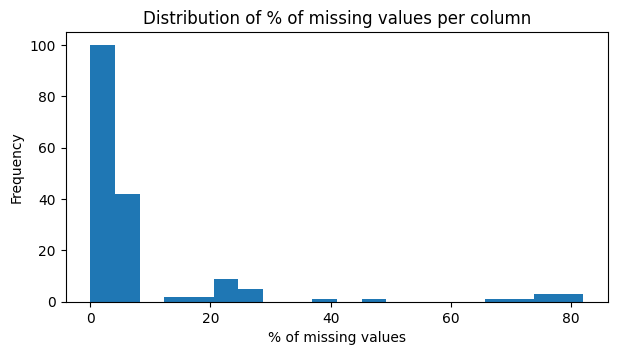

In [5]:
null_pct = (X_train.isna().mean() * 100).sort_values(ascending=False)
print(f"Columns with more than 50% missing values: {(null_pct > 50).sum()} de {X_train.shape[1]}")

fig, ax = plt.subplots(figsize=(7, 3.5))
null_pct.plot(kind="hist", bins=20, ax=ax, title="Distribution of % of missing values per column")
ax.set_xlabel("% of missing values")
plt.show()

In [6]:
# ¿Los camiones con falla tienen más datos faltantes? (la ausencia puede ser informativa)
n_nulos = X_train.isna().sum(axis=1)
n_nulos.groupby(y_train.values).mean().rename({0: "no failures", 1: "with failures"})

no failures      13.912915
with failures    29.153000
dtype: float64

**Observation:** only 8 of 170 columns have more than 50% missing values, but trucks with failures have, on average, more than twice as many missing values per row (29.2 vs 13.9). The absence of data appears to be informative (this is an association; the cause was not investigated), which supports not imputing and letting LightGBM handle missing values natively.

## 3. Model
LightGBM handles missing values natively, so no imputation is done. With only 1,000 failures in train, setting aside 20% as validation would leave ~200: too few to choose a threshold reliably. For this reason, **out-of-sample predictions with cross-validation** (5 folds) are used, which make use of all 1,000 failures.

In [7]:
params = dict(
    n_estimators=300, learning_rate=0.05, num_leaves=31,
    colsample_bytree=0.5, subsample=0.8, subsample_freq=1,
    random_state=42, n_jobs=-1, verbose=-1,
)
model = lgb.LGBMClassifier(**params)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
p_oof = cross_val_predict(model, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

print(f"AUC-PR  (cross validation): {average_precision_score(y_train, p_oof):.4f}  (tasa base: {y_train.mean():.4f})")
print(f"AUC-ROC (cross validation): {roc_auc_score(y_train, p_oof):.4f}")

AUC-PR  (cross validation): 0.8975  (tasa base: 0.0167)
AUC-ROC (cross validation): 0.9890


**Reading:** in cross-validation the PR-AUC is 0.8975, about 54 times the base rate (0.0167), and the ROC-AUC is 0.989. They are not directly comparable with those on test, because the proportion of failures is different.

## 4. Threshold selection by cost
Each threshold is tested and the one that minimizes `10 × FP + 500 × FN` on the out-of-sample predictions from train is chosen.

Optimal threshold: 0.00126
Cost per truck in cross-validation: 0.596


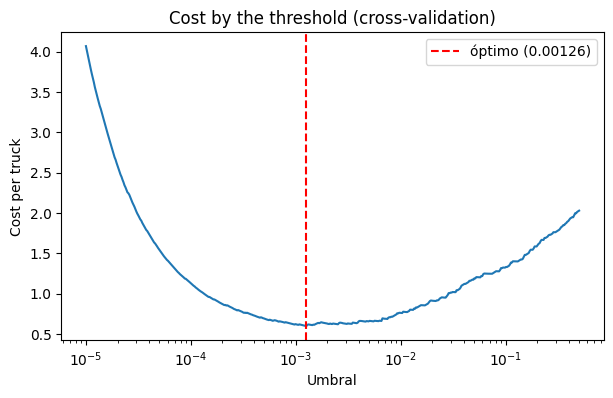

In [8]:
def total_cost(y, p, thr):
    pred = p >= thr
    fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum())
    return COST_FP * fp + COST_FN * fn, fp, fn

y_tr = y_train.values
thresholds = np.logspace(-5, np.log10(0.5), 500)
costs = np.array([total_cost(y_tr, p_oof, t)[0] for t in thresholds])

best_thr = thresholds[costs.argmin()]
print(f"Optimal threshold: {best_thr:.5f}")
print(f"Cost per truck in cross-validation: {costs.min() / len(y_tr):.3f}")
if best_thr in (thresholds[0], thresholds[-1]):
    print("Warning: the optimum is at the edge of the grid; it may be worth widening it.")

plt.figure(figsize=(7, 4))
plt.plot(thresholds, costs / len(y_tr))
plt.axvline(best_thr, color="red", linestyle="--", label=f"óptimo ({best_thr:.5f})")
plt.xlabel("Umbral"); plt.ylabel("Cost per truck")
plt.title("Cost by the threshold (cross-validation)"); plt.legend(); plt.xscale("log")
Path("../reports/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../reports/figures/cost_curve.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading:** the optimal threshold is very low (0.00126). With these costs, the break-even point of a well-calibrated model would be 10 / (10 + 500) ≈ 0.02; the fact that the optimum is much lower suggests that LightGBM's probabilities are not calibrated (hypothesis, not verified). The logarithmic-scale grid prevents the optimum from landing on the edge.

## 5. Result on test (main run, seed 42)
The model is trained on the full train set and the already chosen threshold is applied. This is the main run; in section 6 the procedure is repeated with other seeds to measure the variation.

In [9]:
model.fit(X_train, y_train)
p_test = model.predict_proba(X_test)[:, 1]

cost, fp, fn = total_cost(y_test.values, p_test, best_thr)
print(f"AUC-PR on test:  {average_precision_score(y_test, p_test):.4f}  (base rate: {y_test.mean():.4f})")
print(f"AUC-ROC on test: {roc_auc_score(y_test, p_test):.4f}")
print()
print("Confusion matrix (rows: real; columns: prediction)")
print(pd.DataFrame(confusion_matrix(y_test, p_test >= best_thr),
                   index=["real: no failures", "real: with failures"], columns=["pred: no failures", "pred: with failures"]))

AUC-PR on test:  0.9339  (base rate: 0.0234)
AUC-ROC on test: 0.9967

Confusion matrix (rows: real; columns: prediction)
                     pred: no failures  pred: with failures
real: no failures                15101                  524
real: with failures                  6                  369


In [10]:
comparacion = pd.Series({
    "Inspect none": COST_FN * int(y_test.sum()),
    "Inspect all": COST_FP * int((y_test == 0).sum()),
    f"Model (threshold {best_thr:.5f})": cost,
    "Best result from the IDA 2016 challenge (reference)": 9920,
}, name="total cost on test")
print(f"Model: {fp} unnecessary inspections and {fn} non-detected failures")
comparacion.to_frame()

Model: 524 unnecessary inspections and 6 non-detected failures


,total cost on test
Inspect none,187500
Inspect all,156250
Model (threshold 0.00126),8240
Best result from the IDA 2016 challenge (reference),9920


**Reading of the main run (seed 42):** the model detects 369 of the 375 failures (98.4% recall), with 524 unnecessary inspections (41.3% precision). The total cost is 8,240, 94.7% lower than inspecting all trucks and 95.6% lower than inspecting none.

## 6. Stability of the result across multiple seeds

The result in section 5 comes from a single run. To see how much it varies, **the entire procedure** is repeated with 5 different seeds: cross-validation, threshold selection, and evaluation on test. This way the range also includes how much the chosen threshold changes from one run to another.

**What it covers and what it doesn't:** it covers the variation due to the randomness of training (the model seed and the folds). It does not cover the variation due to the test set, which is fixed and has only 375 failures; with other trucks the cost could be different.

In [12]:
def run_pipeline(seed):
    m = lgb.LGBMClassifier(**{**params, "random_state": seed})
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
    p_oof = cross_val_predict(m, X_train, y_train, cv=cv, method="predict_proba")[:, 1]

    costs = np.array([total_cost(y_tr, p_oof, t)[0] for t in thresholds])
    thr = thresholds[costs.argmin()]

    m.fit(X_train, y_train)
    p_te = m.predict_proba(X_test)[:, 1]
    cost, fp, fn = total_cost(y_test.values, p_te, thr)
    return {"seed": seed, "threshold": thr, "unnecesary_inspections": fp,
            "non-detected_failures": fn, "test_cost": cost}

seeds = [42, 1, 2, 3, 4]
resultados = pd.DataFrame([run_pipeline(s) for s in seeds]).set_index("seed")
resultados

,threshold,unnecesary_inspections,non-detected_failures,test_cost
seed,,,,
42,0.001259,524,6,8240
1,0.001900,449,8,8490
2,0.001286,543,5,7930
3,0.001942,436,10,9360
4,0.001942,438,9,8880


In [ ]:
c = resultados["test_cost"]
print(f"Cost on test: mean {c.mean():,.0f} | desv. {c.std():,.0f} | mín {c.min():,} | máx {c.max():,}")
print("Seeds with the optimum at the edge of the grid:",
      int(resultados["threshold"].isin([thresholds[0], thresholds[-1]]).sum()))

Costo en test: media 8,580 | desv. 558 | mín 7,930 | máx 9,360
Semillas con el óptimo en el borde de la grilla: 0


**Reading:** the cost on test has a mean of 8,580 (std. 558) and a range of 7,930-9,360 across 5 seeds, below the challenge reference (9,920) in every run. The optimal threshold is stable (0.0013-0.0019) and no run left it on the edge of the grid. The variation is explained mostly by the balance between unnecessary inspections (436-543) and undetected failures (5-10). The range does not include the variation due to the test set, which is fixed.

## 7. Conclusions

**Result on test:** mean total cost of 8,580 (std. 558; range 7,930-9,360) across 5 seeds, versus 156,250 when inspecting all trucks and 187,500 when inspecting none (a reduction of ~95%). Recall between 97.3% and 98.7%; precision between 40.5% and 45.6%. PR-AUC 0.934 and ROC-AUC 0.997 (seed 42).

**Reference:** the best result from the IDA 2016 challenge was 9,920. All five runs had a lower cost than the reference, but the range covers only the variation due to training and not that of the test set (375 failures), so it is taken as a reference point and not as outperforming it.

**Observations**
- The optimal threshold is very low (~0.001-0.002), which suggests uncalibrated probabilities.
- The test set has more failures than the train set (2.34% vs 1.67%). Hypothesis (not verified): it may favor an even lower threshold on test.

**Limitations:** anonymized features; no dates, so there is no temporal validation; a single model type without hyperparameter tuning; uncalibrated probabilities; the range across seeds does not include the variation due to the test set.